# Learned meshless FD with a kernel mixture: Test Problem 1

Discretization: the FD solver of `PHS_fd_TP1.m` (fitted interface nodes, one stencil per row, the `nloc` nearest nodes of the same side).

Weights of one stencil: RBF-FD weights of the kernel $K=\sum_k a_k K_k$, $a_k\ge 0$, $\sum_k a_k=1$, with polynomials of degree `deg`.
The dictionary $K_k$ contains PHS $r^3,-r^5,r^7$, Gaussians and Matérn-5/2 kernels (shape parameters in scaled stencil coordinates).
A small network maps the stencil geometry to $a$; every row is exact on the polynomials for every $a$.

Loss (manufactured solutions on the training node sets, new random solutions at every step):
$$L=\frac{\|E\|^2}{\|E_0\|^2}+\lambda\,\frac{\rho}{\rho_0},\qquad E=-A^{-1}\tau,\quad \rho=\operatorname{mean}_i\sum_j|\hat w_{ij}|\,\|\hat y_j\|^{\mu},\ \mu=\texttt{deg},$$
where $E_0,\rho_0$ belong to the baseline (PHS $r^5$ only). The exact solution of the test problem is used only for testing.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt
import lfd
torch.manual_seed(0)

## Settings and training

In [2]:
problem      = lfd.TP1
deg          = 4                 # polynomial degree (nloc = 3Q nearest nodes)
train_levels = [2, 3]            # node levels used for training (uniform and Halton)
steps        = 200               # Adam steps
lam          = 0.1               # weight of the growth term (eq. 20, mu = deg)

model = lfd.MixtureFD(deg=deg)
print('kernels:', model.names)
geoms = [lfd.Geometry(problem, m, nt, deg) for m in train_levels for nt in ('uniform', 'halton')]
print('unknowns per training node set:', [g.N for g in geoms])
hist = lfd.train(model, geoms, steps=steps, nsol=8, lam=lam, log=25)
torch.save(model.state_dict(), f'{problem.name}_mixture_deg{deg}.pt')

kernels: ['phs3', 'phs5', 'phs7', 'gauss3', 'gauss5', 'gauss8', 'matern2', 'matern6']
unknowns per training node set: [486, 503, 1756, 1805]


step    0  validation ||E||^2/||E_0||^2: 1.078  1.165  0.936  1.430


step   25  validation ||E||^2/||E_0||^2: 1.010  0.628  0.986  0.942


step   50  validation ||E||^2/||E_0||^2: 0.274  29.856  0.204  0.291


step   75  validation ||E||^2/||E_0||^2: 0.272  0.181  0.226  0.288


step  100  validation ||E||^2/||E_0||^2: 0.244  0.146  0.188  0.211


step  125  validation ||E||^2/||E_0||^2: 0.206  0.084  0.301  0.310


step  150  validation ||E||^2/||E_0||^2: 0.087  0.058  0.317  0.120


step  175  validation ||E||^2/||E_0||^2: 0.087  0.058  0.317  0.120


step  200  validation ||E||^2/||E_0||^2: 0.087  0.058  0.317  0.120


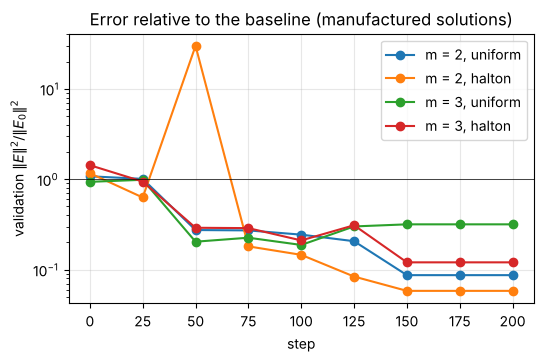

In [3]:
it = [h[0] for h in hist]; V = np.array([h[1] for h in hist])
plt.figure(figsize=(6, 3.5))
for j, g in enumerate(geoms):
    plt.semilogy(it, V[:, j], 'o-', label=f'm = {g.m}, {g.ntype}')
plt.axhline(1, color='k', lw=0.5); plt.xlabel('step'); plt.ylabel(r'validation $\|E\|^2/\|E_0\|^2$')
plt.legend(); plt.grid(alpha=0.3); plt.title('Error relative to the baseline (manufactured solutions)'); plt.show()

## What the network learned
Mean mixture coefficients over the Laplacian rows and over the flux rows.

In [4]:
np.set_printoptions(precision=3, suppress=True, linewidth=150)
print(' ' * 22, '  '.join(f'{n:>7}' for n in model.names))
for nt in ('uniform', 'halton'):
    g = lfd.Geometry(problem, 3, nt, deg)
    lap, dn = model.mixture_map(g)
    print(f'{nt:8s} Laplacian rows', '  '.join(f'{v:7.3f}' for v in lap.mean(0)))
    print(f'{nt:8s} flux rows     ', '  '.join(f'{v:7.3f}' for v in dn.mean(0)))

                          phs3     phs5     phs7   gauss3   gauss5   gauss8  matern2  matern6
uniform  Laplacian rows   0.000    0.000    1.000    0.000    0.000    0.000    0.000    0.000
uniform  flux rows        0.000    0.000    1.000    0.000    0.000    0.000    0.000    0.000
halton   Laplacian rows   0.000    0.000    1.000    0.000    0.000    0.000    0.000    0.000
halton   flux rows        0.000    0.000    1.000    0.000    0.000    0.000    0.000    0.000


## Test Problem 1: baseline (PHS $r^5$) against the learned mixture
Errors over the interior nodes; `sigma` estimates $\|A^{-1}\|_\infty$.

In [5]:
levels = range(0, 5)
res = {nt: lfd.table(model, problem, levels, nt) for nt in ('uniform', 'halton')}

TP1, FD, degree 4, uniform nodes: baseline (phs5) vs learned mixture
 m        h    Nint |   rms base   max base     sigma |  rms learn  max learn     sigma | rms ratio
 0  0.40000      12 |  1.433e-01  3.567e-01  6.89e+00 |  1.485e-01  3.675e-01  1.41e+01 |     1.036


 1  0.20000      76 |  2.064e-02  6.082e-02  1.70e+01 |  1.381e-02  4.027e-02  5.36e+01 |     0.669


 2  0.10000     350 |  7.662e-04  2.386e-03  8.26e+00 |  5.551e-04  1.706e-03  1.40e+01 |     0.724


 3  0.05000    1492 |  4.529e-05  1.189e-04  1.20e+01 |  2.029e-05  6.030e-05  1.46e+01 |     0.448


 4  0.02500    6178 |  1.740e-06  4.200e-06       nan |  8.822e-07  3.412e-06       nan |     0.507
TP1, FD, degree 4, halton nodes: baseline (phs5) vs learned mixture
 m        h    Nint |   rms base   max base     sigma |  rms learn  max learn     sigma | rms ratio
 0  0.40000      19 |  3.191e-02  7.407e-02  5.32e+00 |  1.833e-02  4.339e-02  6.53e+00 |     0.574
 1  0.20000      80 |  1.191e-02  3.514e-02  1.49e+01 |  5.977e-03  1.638e-02  1.86e+01 |     0.502


 2  0.10000     367 |  4.514e-04  1.847e-03  2.17e+01 |  1.557e-04  5.466e-04  1.74e+01 |     0.345


 3  0.05000    1541 |  5.146e-05  1.611e-04  7.74e+01 |  2.842e-05  1.655e-04  1.04e+02 |     0.552


 4  0.02500    6265 |  7.541e-06  4.183e-05       nan |  9.757e-07  6.032e-06       nan |     0.129


## Reference: each dictionary kernel alone
Classical RBF-FD with one kernel (same stencils, same polynomial degree).

In [6]:
single = {nt: lfd.single_kernel_table(model, problem, levels, nt) for nt in ('uniform', 'halton')}

TP1, FD, degree 4, uniform nodes: rms error with one kernel only
   kernel        m=0        m=1        m=2        m=3        m=4


     phs3  1.344e-01  2.274e-02  9.153e-04  5.994e-05  3.594e-06


     phs5  1.433e-01  2.064e-02  7.662e-04  4.529e-05  1.740e-06


     phs7  1.485e-01  1.381e-02  5.551e-04  2.029e-05  8.822e-07


   gauss3  1.473e-01  2.210e-02  1.110e-03  4.290e-05  1.898e-06


   gauss5  1.408e-01  5.849e-02  1.345e-03  6.923e-05  1.030e-05


... (7 outputs left out)

   gauss5  5.409e-02  3.759e-02  2.852e-03  1.687e-04  1.920e-05


   gauss8  6.273e-02  5.799e-02  5.711e-03  8.786e-04  4.883e-04


  matern2  3.383e-02  1.343e-02  5.787e-04  4.520e-05  2.916e-05


  matern6  4.062e-02  2.002e-02  9.448e-04  7.924e-05  7.649e-06


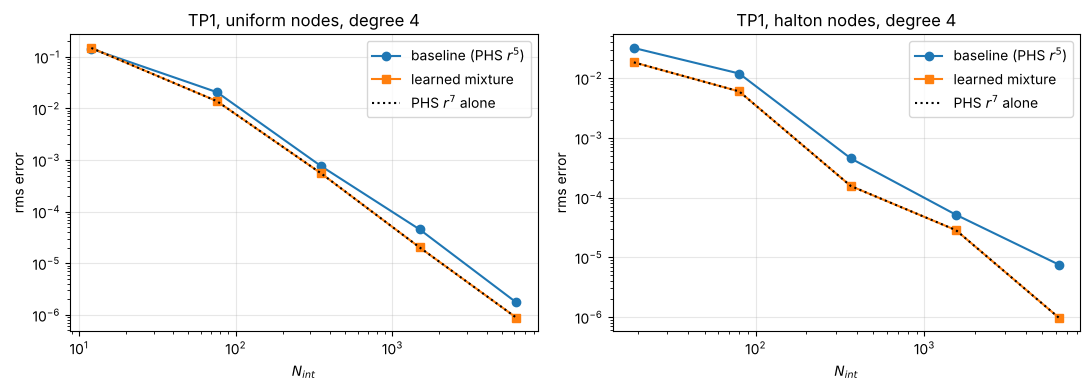

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, nt in zip(ax, ('uniform', 'halton')):
    N = [r[2]['Nint'] for r in res[nt]]
    a.loglog(N, [r[2]['rms'] for r in res[nt]], 'o-', label='baseline (PHS $r^5$)')
    a.loglog(N, [r[3]['rms'] for r in res[nt]], 's-', label='learned mixture')
    a.loglog(N, single[nt]['phs7'], 'k:', label='PHS $r^7$ alone')
    a.set_xlabel('$N_{int}$'); a.set_ylabel('rms error'); a.set_title(f'{problem.name}, {nt} nodes, degree {deg}')
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()